# T4.1 — Padronização das imagens

Define e aplica o processamento de entrada do modelo: orientação EXIF, conversão para RGB, redimensionamento preservando a proporção, preenchimento neutro e normalização para [0, 1]. A lógica está em [`src/preprocessamento.py`](../src/preprocessamento.py) e é a mesma usada no treinamento e na inferência.

**Entrada:** o manifesto da T4.2 (`assets/data/particionamento_T4_2/manifesto_provisorio.csv`), com apenas as imagens marcadas como *manter*.

**Dependências:** `pandas`, `pillow`, `numpy` e Jupyter.

> **Caminho da base:** ajuste `RAIZ_IMAGENS` para a pasta que contém `dataset/` (disco local, Google Drive montado no Colab ou outro local).

In [1]:
from pathlib import Path
import hashlib
import json
import sys

import pandas as pd
import PIL
from IPython.display import display
from PIL import Image, ImageOps

ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "assets/data/particionamento_T4_2/manifesto_provisorio.csv").exists()
)
sys.path.insert(0, str(ROOT / "src"))
from preprocessamento import COR_PREENCHIMENTO, TAMANHO_ENTRADA, preparar_imagem

# Pasta que contém dataset/. No Colab, por exemplo: Path("/content/drive/MyDrive/...")
RAIZ_IMAGENS = Path("C:/Users/Inteli/OneDrive/Desktop/Agro App")
MANIFESTO = ROOT / "assets/data/particionamento_T4_2/manifesto_provisorio.csv"
SAIDA = ROOT / "assets/data/padronizacao_T4_1"

manifesto = pd.read_csv(MANIFESTO, encoding="utf-8-sig")
print("Imagens no manifesto:", len(manifesto))
print("Tamanho de entrada:", TAMANHO_ENTRADA, "| cor de preenchimento:", COR_PREENCHIMENTO)

Imagens no manifesto: 3262
Tamanho de entrada: 224 | cor de preenchimento: (128, 128, 128)


In [2]:
# Confere a base antes de processar. Interrompe com a lista do que falta.
prefixos = manifesto["caminho_relativo"].str.split("/").str[0].unique()
faltando = [pref for pref in prefixos if not (RAIZ_IMAGENS / pref).is_dir()]
if faltando:
    raise FileNotFoundError(
        f"RAIZ_IMAGENS = {RAIZ_IMAGENS.resolve()}\n"
        f"Pastas não encontradas nessa raiz: {faltando}\n"
        "Ajuste RAIZ_IMAGENS para a pasta que contém dataset/, Soja/ e Milho/."
    )
print("Base encontrada em:", RAIZ_IMAGENS.resolve())

Base encontrada em: C:\Users\Inteli\OneDrive\Desktop\Agro App


## 1. Distribuição das dimensões

Lê apenas o cabeçalho de cada arquivo, sem decodificar os pixels. Serve para conferir se 224 px é uma entrada razoável: a menor dimensão precisa caber no alvo sem ampliação excessiva.

In [3]:
registros = []
for linha in manifesto.itertuples(index=False):
    try:
        with Image.open(RAIZ_IMAGENS / linha.caminho_relativo) as imagem:
            registros.append((linha.image_id, imagem.width, imagem.height, None))
    except OSError as erro:
        registros.append((linha.image_id, None, None, str(erro)))

dimensoes = pd.DataFrame(registros, columns=["image_id", "largura", "altura", "erro"])
dimensoes["menor_dimensao"] = dimensoes[["largura", "altura"]].min(axis=1)
print("Falhas de leitura:", dimensoes["erro"].notna().sum())
print("Menor dimensão abaixo de 224 px:", (dimensoes["menor_dimensao"] < TAMANHO_ENTRADA).sum())
display(dimensoes[["largura", "altura", "menor_dimensao"]].describe().round(1))

Falhas de leitura: 0
Menor dimensão abaixo de 224 px: 79


,largura,altura,menor_dimensao
count,3262.0,3262.0,3262.0
mean,743.0,749.2,632.1
std,312.6,296.0,238.2
min,88.0,100.0,88.0
25%,500.0,563.2,500.0
50%,768.0,722.0,682.0
75%,1024.0,1024.0,768.0
max,4608.0,3468.0,2601.0


## 2. Inspeção visual

Uma amostra fixa de 8 imagens: a linha de cima é a original (ajustada apenas para exibição) e a de baixo é a saída de `preparar_imagem`.

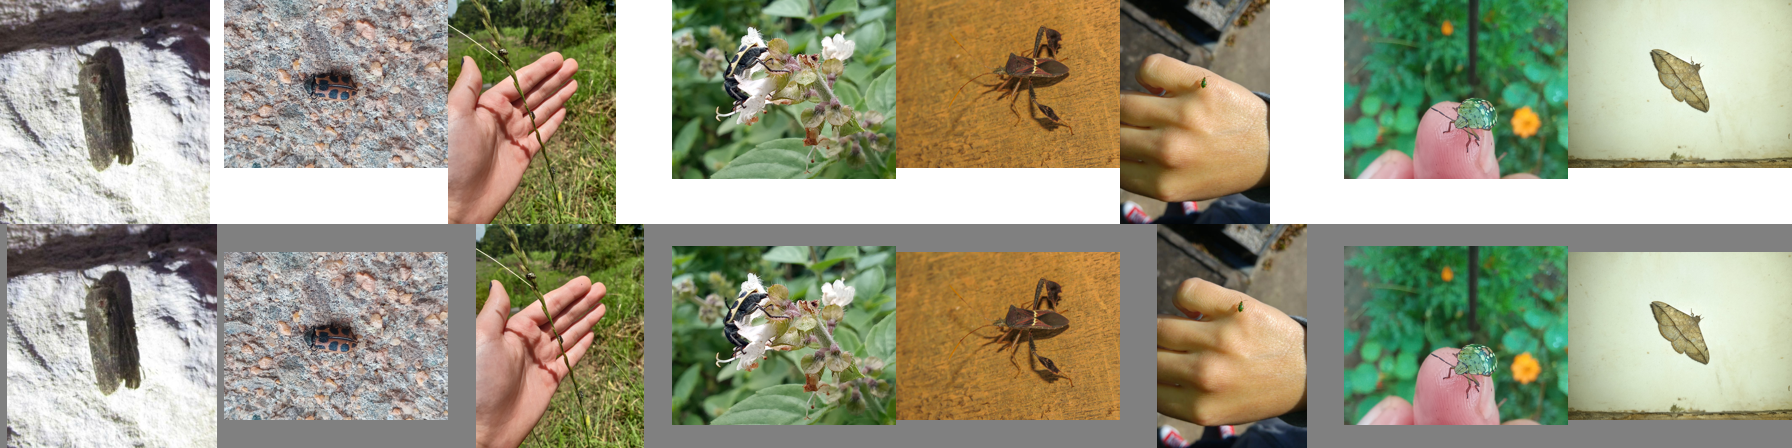

In [4]:
amostra = manifesto.sample(8, random_state=42)
largura = TAMANHO_ENTRADA
grade = Image.new("RGB", (largura * len(amostra), largura * 2), (255, 255, 255))

for i, linha in enumerate(amostra.itertuples(index=False)):
    with Image.open(RAIZ_IMAGENS / linha.caminho_relativo) as original:
        original_ajustada = ImageOps.contain(ImageOps.exif_transpose(original).convert("RGB"), (largura, largura))
        grade.paste(original_ajustada, (i * largura, 0))
        preparada = Image.fromarray((preparar_imagem(original) * 255).round().astype("uint8"))
        grade.paste(preparada, (i * largura, largura))

display(grade)

## 3. Verificação em todo o conjunto

Aplica `preparar_imagem` a todas as imagens do manifesto, confirma forma e faixa de valores e calcula um hash da saída. O hash permite comparar a implementação no aparelho com a referência gerada aqui.

In [5]:
hashes = []
falhas = []
for linha in manifesto.itertuples(index=False):
    try:
        entrada = preparar_imagem(RAIZ_IMAGENS / linha.caminho_relativo)
    except OSError as erro:
        falhas.append({"image_id": linha.image_id, "erro": str(erro)})
        continue
    assert entrada.shape == (TAMANHO_ENTRADA, TAMANHO_ENTRADA, 3), linha.image_id
    assert entrada.min() >= 0 and entrada.max() <= 1, linha.image_id
    hashes.append({
        "image_id": linha.image_id,
        "particao": linha.particao,
        "sha256_entrada": hashlib.sha256(entrada.tobytes()).hexdigest(),
    })

referencia = pd.DataFrame(hashes)
print(f"Processadas: {len(referencia)} | falhas de leitura: {len(falhas)}")
display(referencia["particao"].value_counts().rename("imagens").to_frame())

Processadas: 3262 | falhas de leitura: 0


,imagens
particao,
treino,2287
validacao,488
teste,487


## 4. Exportação

Grava a referência de hashes e os parâmetros usados. Os arquivos ficam em `assets/data/padronizacao_T4_1/`.

In [6]:
SAIDA.mkdir(parents=True, exist_ok=True)
referencia.to_csv(SAIDA / "referencia_entrada.csv", index=False, encoding="utf-8-sig")
(SAIDA / "parametros.json").write_text(
    json.dumps({
        "tamanho_entrada": TAMANHO_ENTRADA,
        "cor_preenchimento": list(COR_PREENCHIMENTO),
        "redimensionamento": "proporcional, sem recorte, reamostragem bicubica",
        "normalizacao": "float32 em [0, 1]",
        "orientacao": "EXIF aplicada antes do redimensionamento",
        "pillow": PIL.__version__,
        "falhas_de_leitura": falhas,
    }, ensure_ascii=False, indent=2),
    encoding="utf-8",
)
print("Gravado em:", SAIDA.relative_to(ROOT))

Gravado em: assets\data\padronizacao_T4_1


## Decisões registradas

| Decisão | Escolha | Motivo |
| --- | --- | --- |
| Tamanho de entrada | 224 × 224 | Referência do diagnóstico da T3.3; candidato EfficientNet-Lite0. Parametrizado, pois o backbone final ainda não foi escolhido. |
| Redimensionamento | Proporcional, com preenchimento cinza | Evita recorte, que poderia cortar lesões nas bordas, e não distorce a forma das folhas. |
| Normalização | [0, 1] em float32 | Simples e portável para a inferência no aparelho. Confirmar a faixa esperada pelo backbone antes do treinamento. |
| Orientação EXIF | Aplicada | Fotos de celular podem estar giradas no arquivo. |

**Próximos passos:** confirmar a faixa de normalização do backbone escolhido, usar `preparar_imagem` na T4.4 e replicar a referência de hashes na implementação de inferência.